# Numerical Methods in Mechanical Engineering
## Fall 2026, Week #8 - Lab Assignment

**Name:** ___________________  
**Date:** ___________________

*Instructions: Fill in the missing code in the cells below to complete the assignment. Write your comments in the markdown cells marked* **Your comments**.

In [113]:
import numpy as np
import matplotlib.pyplot as plt

# Set print options and a clean plot style
np.set_printoptions(precision=6, suppress=True)
plt.style.use('seaborn-v0_8-whitegrid')

### Setup: Test Problem
All solvers take the inputs `(f, t0, y0, h, n)`, where `f(t, y)` is a Python function and `n` is the number of steps, and return arrays `t` and `y` of length $n+1$.

Unless stated otherwise, the test problem is
$$
y' = -2ty^2, \qquad y(0) = 1, \qquad \text{exact solution } y(t) = \frac{1}{1+t^2}.
$$

In [114]:
# Test problem (given): y' = -2 t y^2, y(0) = 1
def f_test(t, y):
    return -2 * t * y**2

def dfdy_test(t, y):          # partial derivative df/dy (needed for backward Euler)
    return -4 * t * y

def y_exact(t):
    return 1 / (1 + np.asarray(t, dtype=float)**2)

### Problem 1: Solving ODEs [1.0 pts]
Implement and compare basic numerical methods for solving ODEs.

#### Problem 1(a): Euler's Methods [0.25 pts]
$$
\text{forward: } y_{k+1}=y_k+h\,f(t_k,y_k), \qquad \text{backward: } y_{k+1}=y_k+h\,f(t_{k+1},y_{k+1})
$$
For backward Euler, solve $g(z)=z-y_k-h\,f(t_{k+1},z)=0$ at each step with Newton's method (from Week 5), using $g'(z)=1-h\,\partial f/\partial y$ and the forward Euler step as the initial guess.

Test on $y'=-y^3$, $y(0)=1$, $h=0.5$, one step. Compare with the exact value $y(0.5)=1/\sqrt{2}$.

In [115]:
# Newton's method (from Week 5)
def newton(f, df, x0, tol=1e-10, max_iter=100):
    x = x0

    for k in range(1, max_iter + 1):
      x_new = x - f(x) / df(x)

      if abs(x_new - x) < tol:
        return x_new, k

      x = x_new

    return x, max_iter


def euler(f, t0, y0, h, n, method='forward', dfdy=None):
    t = t0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[0] = y0

    for k in range(n):
      y_fwd = y[k] + h * f(t[k], y[k])

      if method == 'forward':
        y[k + 1] = y_fwd

      elif method == 'backward':
        g = lambda z: z - y[k] - h * f(t[k + 1], z)
        dg = lambda z: 1 - h * dfdy(t[k + 1], z)

        y[k + 1], _ = newton(g, dg, y_fwd)


      else:
        raise ValueError("method must be 'forward' or 'backward'")


    return t, y


# --- Test: y' = -y^3, y(0) = 1, h = 0.5, one step ---
f_cubic    = lambda t, y: -y**3
dfdy_cubic = lambda t, y: -3 * y**2

_, y_fe = euler(f_cubic, 0, 1, 0.5, 1, method='forward')
_, y_be = euler(f_cubic, 0, 1, 0.5, 1, method='backward', dfdy=dfdy_cubic)

print("Problem 1(a)")
print(f"Forward Euler  y1 = {y_fe[1]:.6f}")
print(f"Backward Euler y1 = {y_be[1]:.6f}")
print(f"Exact      y(0.5) = {1/np.sqrt(2):.6f}")

Problem 1(a)
Forward Euler  y1 = 0.500000
Backward Euler y1 = 0.770917
Exact      y(0.5) = 0.707107


#### Problem 1(b): RK2 [0.15 pts]
$$
k_1=h\,f(t_k,y_k), \quad k_2=h\,f(t_{k+1},\,y_k+k_1), \quad y_{k+1}=y_k+\tfrac{1}{2}(k_1+k_2)
$$
Test on the test problem with $h=0.25$, two steps. Verify $y_1=0.9375$ and $y_2\approx0.7969$.

In [116]:
def rk2(f, t0, y0, h, n):
    t = t0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[0] = y0

    for k in range(n):
      k1 = h * f(t[k], y[k])
      k2 = h * f(t[k + 1], y[k] + k1)

      y[k + 1] = y[k] + 0.5 * (k1 + k2)

    return t, y


# --- Test: h = 0.25, two steps ---
t_rk2, y_rk2 = rk2(f_test, 0, 1, 0.25, 2)
print("Problem 1(b)")
print(f"RK2: y1 = {y_rk2[1]:.4f}, y2 = {y_rk2[2]:.4f}")

Problem 1(b)
RK2: y1 = 0.9375, y2 = 0.7969


#### Problem 1(c): RK4 [0.15 pts]
$$
k_1=h f(t_k,y_k),\quad k_2=h f\!\left(t_k+\tfrac{h}{2},y_k+\tfrac{k_1}{2}\right),\quad
k_3=h f\!\left(t_k+\tfrac{h}{2},y_k+\tfrac{k_2}{2}\right),\quad k_4=h f(t_k+h,y_k+k_3)
$$
$$
y_{k+1}=y_k+\tfrac{1}{6}(k_1+2k_2+2k_3+k_4)
$$
Repeat the test of part (b) and print `rk2`, `rk4`, and the exact solution side by side.

In [117]:
def rk4(f, t0, y0, h, n):
    t = t0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[0] = y0

    for k in range(n):
      k1 = h * f(t[k], y[k])
      k2 = h * f(t[k] + h/2, y[k] + k1/2)
      k3 = h * f(t[k] + h/2, y[k] + k2/2)
      k4 = h * f(t[k] + h, y[k] + k3)

      y[k + 1] = y[k] + (k1 + 2*k2 + 2*k3 + k4) / 6

    return t, y


# --- Test: h = 0.25, two steps, side-by-side comparison ---
t_rk4, y_rk4 = rk4(f_test, 0, 1, 0.25, 2)

print("Problem 1(c)")
print(f"{'k':<3} | {'t_k':<6} | {'RK2':<10} | {'RK4':<10} | {'Exact':<10}")
print("-" * 50)
for k in range(3):
    print(f"{k:<3} | {t_rk4[k]:<6.2f} | {y_rk2[k]:<10.6f} | {y_rk4[k]:<10.6f} | {y_exact(t_rk4[k]):<10.6f}")

Problem 1(c)
k   | t_k    | RK2        | RK4        | Exact     
--------------------------------------------------
0   | 0.00   | 1.000000   | 1.000000   | 1.000000  
1   | 0.25   | 0.937500   | 0.941154   | 0.941176  
2   | 0.50   | 0.796946   | 0.799948   | 0.800000  


#### Problem 1(d): Multistep Method [0.15 pts]
$$
y_{k+1}=y_k+\tfrac{h}{2}\big(3f(t_k,y_k)-f(t_{k-1},y_{k-1})\big)
$$
Use one step of `rk2` to obtain $y_1$. Test with $h=0.25$, two steps, and verify $y_2\approx0.7727$.

In [118]:
def multistep2(f, t0, y0, h, n):
    t = t0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[0] = y0

    _, y_start = rk2(f, t0, y0, h, 1)
    y[1] = y_start[1]

    for k in range(1, n):
        y[k + 1] = y[k] + (h / 2) * (3 * f(t[k], y[k]) - f(t[k - 1], y[k - 1]))


    return t, y


# --- Test: h = 0.25, two steps ---
_, y_ms2_test = multistep2(f_test, 0, 1, 0.25, 2)

print("Problem 1(d)")
print(f"y1 = {y_ms2_test[1]: .4f}")
print(f"y2 = {y_ms2_test[2]: .4f}")

Problem 1(d)
y1 =  0.9375
y2 =  0.7727


#### Problem 1(e): Comparison [0.3 pts]
**(i) Accuracy:** Solve the test problem over $t\in[0,2]$ with $h=0.1$ using forward Euler, backward Euler, RK2, RK4, and the 2-step method. Plot all solutions with the exact solution, and print the absolute error at $t=2$, ordered from least to most accurate.

**(ii) Stability:** Solve $y'=\lambda y$, $\lambda=-20$, $y(0)=1$, over $t\in[0,1.2]$ using forward Euler, backward Euler, and RK4 with $h=0.08$ and $h=0.12$ (one figure per step size, exact solution $e^{\lambda t}$ included). Print the growth factors $|1+h\lambda|$ and $|1/(1-h\lambda)|$ for each $h$.

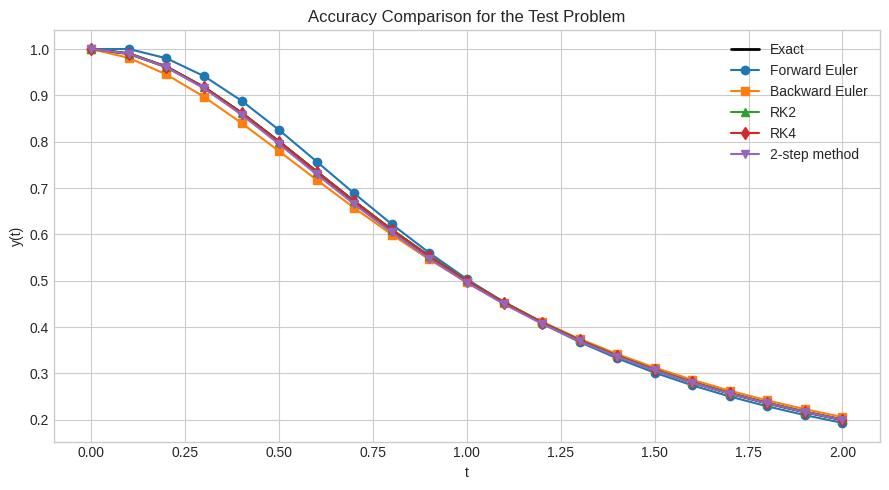

Absolute errors at t = 2
(least to most accurate)
Method                 Absolute error
-------------------------------------
Forward Euler          6.65810092e-03
Backward Euler         5.97820554e-03
RK2                    6.94563349e-04
2-step method          4.81267040e-05
RK4                    6.54116058e-07


In [119]:
# --- (i) Accuracy: test problem on [0, 2], h = 0.1 ---
h, T = 0.1, 2.0
n = int(round(T / h))

t, y_fe = euler(f_test, 0, 1, h, n, method='forward')

_, y_be = euler(f_test, 0, 1, h, n, method='backward', dfdy=dfdy_test)

_, y_rk2 = rk2(f_test, 0, 1, h, n)
_, y_rk4 = rk4(f_test, 0, 1, h, n)
_, y_ms2 = multistep2(f_test, 0, 1, h, n)

plt.figure(figsize=(9, 5))

plt.plot(t, y_exact(t), 'k-', linewidth=2, label='Exact')
plt.plot(t, y_fe, 'o-', label='Forward Euler')
plt.plot(t, y_be, 's-', label='Backward Euler')
plt.plot(t, y_rk2, '^-', label='RK2')
plt.plot(t, y_rk4, 'd-', label='RK4')
plt.plot(t, y_ms2, 'v-', label='2-step method')

plt.title('Accuracy Comparison for the Test Problem')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend()
plt.tight_layout()
plt.show()

errors = [
    ('Forward Euler', abs(y_fe[-1] - y_exact(T))),
    ('Backward Euler', abs(y_be[-1] - y_exact(T))),
    ('RK2', abs(y_rk2[-1] - y_exact(T))),
    ('RK4', abs(y_rk4[-1] - y_exact(T))),
    ('2-step method', abs(y_ms2[-1] - y_exact(T))),
]

errors.sort(key=lambda item: item[1], reverse=True)

print("Absolute errors at t = 2")
print("(least to most accurate)")
print(f"{'Method' :<18} {'Absolute error' :>18}")
print("-" * 37)

for method, error in errors:
    print(f"{method:<18} {error:>18.8e}")

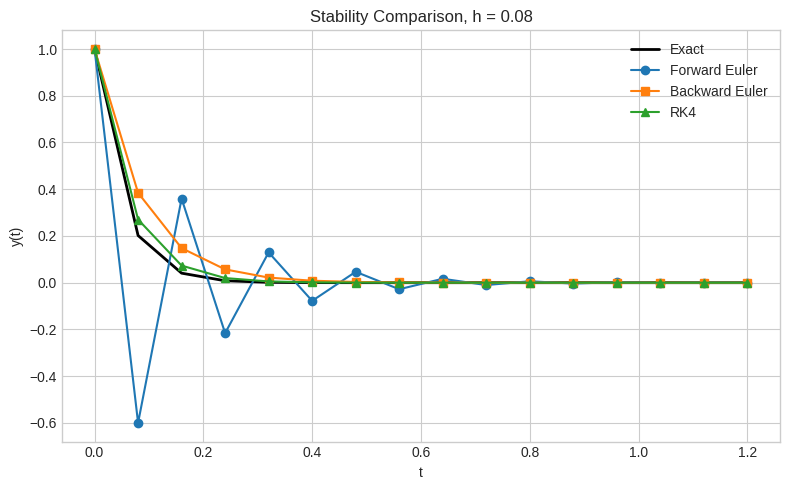

h = 0.08
Forward Euler growth factor = 0.600000
Backward Euler growth factor = 0.384615



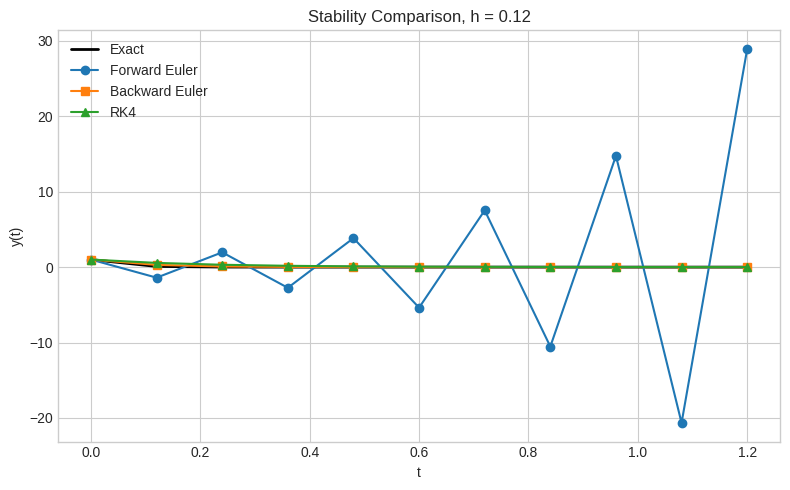

h = 0.12
Forward Euler growth factor = 1.400000
Backward Euler growth factor = 0.294118

Forward Euler stability limit: h <= 0.10


In [120]:
# --- (ii) Stability: y' = lambda*y, lambda = -20, on [0, 1.2] ---
lam = -20.0
T = 1.2

f_stability = lambda t, y: lam * y
dfdy_stability = lambda t, y: lam

for h in [0.08, 0.12]:
    n = int(round(T / h))

    t_stab, y_fe_stab = euler(f_stability, 0, 1, h, n, method='forward')

    _, y_be_stab = euler(f_stability, 0, 1, h, n, method='backward', dfdy=dfdy_stability)

    _, y_rk4_stab = rk4(f_stability, 0, 1, h, n)

    plt.figure(figsize=(8, 5))

    plt.plot(t_stab, np.exp(lam * t_stab), 'k', linewidth=2, label="Exact")

    plt.plot(t_stab, y_fe_stab, 'o-', label='Forward Euler')
    plt.plot(t_stab, y_be_stab, 's-', label='Backward Euler')
    plt.plot(t_stab, y_rk4_stab, '^-', label='RK4')

    plt.title(f'Stability Comparison, h = {h}')
    plt.xlabel('t')
    plt.ylabel('y(t)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    fe_factor = abs(1 + h * lam)
    be_factor = abs(1 / (1 - h * lam))

    print(f"h = {h:.2f}")
    print(f"Forward Euler growth factor = {fe_factor:.6f}")
    print(f"Backward Euler growth factor = {be_factor:.6f}")
    print()

stability_limit = -2 / lam

print(f"Forward Euler stability limit: h <= {stability_limit:.2f}")

### Problem 2: Adams–Bashforth [0.4 pts]
$$
y_{k+1}=y_k+\tfrac{h}{24}\big(55f_k-59f_{k-1}+37f_{k-2}-9f_{k-3}\big), \qquad f_j=f(t_j,y_j)
$$

#### Problem 2(a): Implementation [0.2 pts]
Use your `rk4` function to generate the starting values $y_1, y_2, y_3$.

In [121]:
def adams_bashforth4(f, t0, y0, h, n):
    t = t0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)

    _, y_start = rk4(f, t0, y0, h, 3)
    y[:4] = y_start

    for k in range(3, n):
        fk = f(t[k], y[k])
        fk1 = f(t[k - 1], y[k - 1])
        fk2 = f(t[k - 2], y[k - 2])
        fk3 = f(t[k - 3], y[k - 3])

        y[k + 1] = y[k] + (h / 24) * (55 * fk - 59 * fk1 + 37 * fk2 - 9 * fk3)


    return t, y

t_2a, y_2a = adams_bashforth4(f_test, 0, 1, 0.1, 20)

print("Problem 2(a)")
print("t=", t_2a)
print("y=", y_2a)

Problem 2(a)
t= [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7
 1.8 1.9 2. ]
y= [1.       0.990099 0.961538 0.917431 0.862389 0.800527 0.735944 0.671754
 0.610267 0.55285  0.500237 0.452618 0.409896 0.371759 0.337826 0.307666
 0.28087  0.25704  0.235823 0.216897 0.199981]


#### Problem 2(b): Accuracy vs. Cost [0.2 pts]
Solve the test problem over $t\in[0,2]$ with $h=0.1$. Plot against the exact solution, print the absolute error at $t=2$, and compare it with RK4 and the 2-step method from Problem 1(e).

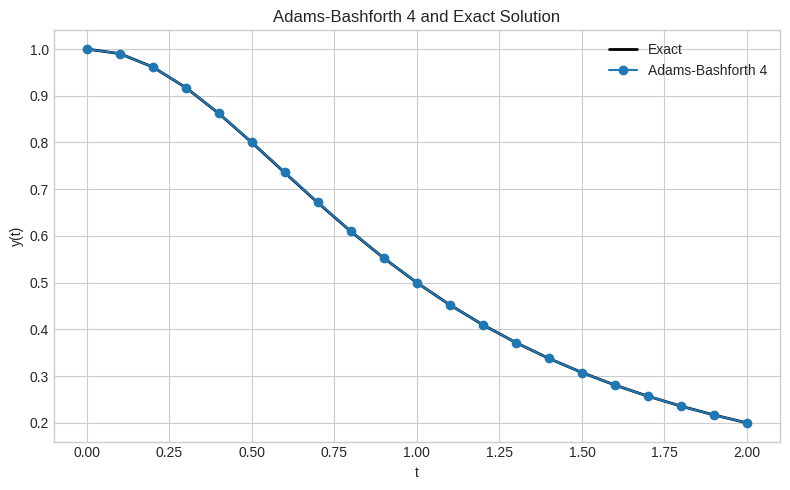

Problem 2(b): Absolute errors at t = 2
Method                     Absolute error
-----------------------------------------
Adams Bashforth 4          1.88626114e-05
RK4                        6.54116058e-07
2-step method              4.81267040e-05


In [122]:
h, T = 0.1, 2.0
n = int(round(T / h))

t_ab4, y_ab4 = adams_bashforth4(f_test, 0, 1, h, n)

plt.figure(figsize=(8, 5))

plt.plot(t_ab4, y_exact(t_ab4), 'k-', linewidth=2, label='Exact')

plt.plot(t_ab4, y_ab4, 'o-', label='Adams-Bashforth 4')

plt.title('Adams-Bashforth 4 and Exact Solution')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend()
plt.tight_layout()
plt.show()

ab4_error = abs(y_ab4[-1] - y_exact(T))
rk4_error = abs(y_rk4[-1] - y_exact(T))
ms2_error = abs(y_ms2[-1] - y_exact(T))

print("Problem 2(b): Absolute errors at t = 2")
print(f"{'Method':<22} {'Absolute error':>18}")
print("-" * 41)
print(f"{'Adams Bashforth 4':<22} {ab4_error:>18.8e}")
print(f"{'RK4':<22} {rk4_error:>18.8e}")
print(f"{'2-step method':<22} {ms2_error:>18.8e}")

### Problem 3: Adams–Moulton with Repeated Correction [0.6 pts]
Predict $y^{(0)}_{k+1}$ with Adams–Bashforth (Problem 2), then iterate the Adams–Moulton corrector
$$
y^{(m+1)}_{k+1}=y_k+\tfrac{h}{24}\big(9f(t_{k+1},y^{(m)}_{k+1})+19f_k-5f_{k-1}+f_{k-2}\big)
$$
until $|y^{(m+1)}_{k+1}-y^{(m)}_{k+1}|<\texttt{tol}$ or `max_iter` is reached.

#### Problem 3(a): Implementation [0.3 pts]
Also return the list of corrector iterations used at each step. Use `rk4` for $y_1, y_2, y_3$.

In [123]:
def adams_moulton4(f, t0, y0, h, n, tol=1e-10, max_iter=20):
    t = t0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    iters = []

    _, y_start = rk4(f, t0, y0, h, 3)
    y[:4] = y_start

    for k in range (3, n):
        fk = f(t[k], y[k])
        fk1 = f(t[k - 1], y[k - 1])
        fk2 = f(t[k - 2], y[k - 2])
        fk3 = f(t[k - 3], y[k - 3])

        y_pred = y[k] + (h / 24) * (55 * fk - 59 * fk1 + 37 * fk2 - 9 * fk3)

        for m in range(1, max_iter + 1):
            y_corr = y[k] + (h / 24) * (
                9 * f(t[k+1], y_pred)
                + 19 * fk
                - 5 * fk1
                + fk2
            )

            converged = abs(y_corr - y_pred) < tol
            y_pred = y_corr

            if converged:
                break

        y[k + 1] = y_corr
        iters.append(m)

    return t, y, iters

t_3a, y_3a, iters_3a = adams_moulton4(f_test, 0, 1, 0.25, 8)

print("Problem 3(a)")
print("t=", t_3a)
print("y=", y_3a)
print("Corrector iterations =", iters_3a)

Problem 3(a)
t= [0.   0.25 0.5  0.75 1.   1.25 1.5  1.75 2.  ]
y= [1.       0.941154 0.799948 0.639974 0.500189 0.390709 0.308135 0.246489
 0.200228]
Corrector iterations = [13, 12, 12, 11, 10]


#### Problem 3(b): Effect of Repeated Correction [0.3 pts]
Solve the test problem over $t\in[0,2]$ with $h=0.25$. Print the corrector iterations per step, then rerun with `max_iter=1`. Print the absolute error at $t=2$ for Adams–Bashforth alone, a single correction, and repeated correction, and plot all three against the exact solution.

Corrector iterations per step:
t = 1.00: 13 iterations
t = 1.25: 12 iterations
t = 1.50: 12 iterations
t = 1.75: 11 iterations
t = 2.00: 10 iterations
Absolute errors at t = 2:
Adams Bashforth alone: 1.49205485e-02
Single Correction:     7.86354562e-04
Repeated Correction:   2.28178488e-04


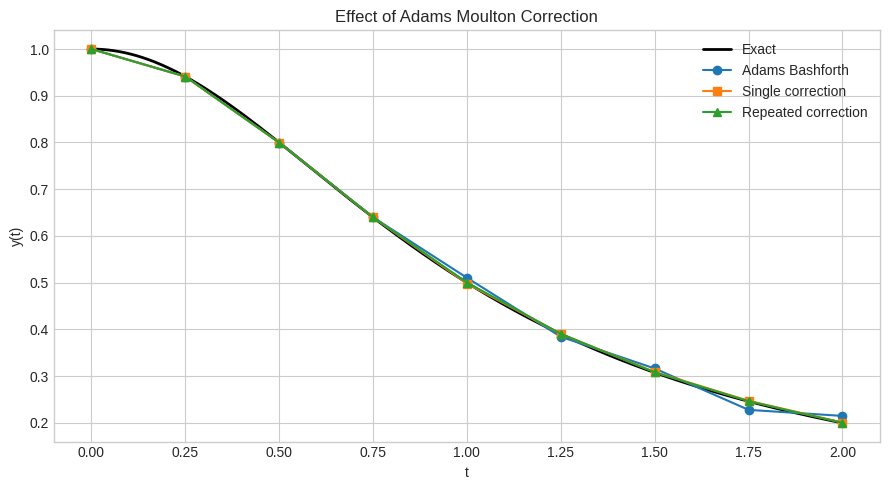

In [124]:
h, T = 0.25, 2.0
n = int(round(T / h))

t_rep, y_rep, iters_rep = adams_moulton4(f_test, 0, 1, h, n)

t_single, y_single, _ = adams_moulton4(f_test, 0, 1, h, n, max_iter=1)

t_ab, y_ab = adams_bashforth4(f_test, 0, 1, h, n)

print("Corrector iterations per step:")

for k, count in enumerate(iters_rep, start=4):
    print(f"t = {t_rep[k]:.2f}: {count} iterations")

ab_error = abs(y_ab[-1] - y_exact(T))
single_error = abs(y_single[-1] - y_exact(T))
repeated_error = abs(y_rep[-1] - y_exact(T))

print("Absolute errors at t = 2:")
print(f"Adams Bashforth alone: {ab_error:.8e}")
print(f"Single Correction:     {single_error:.8e}")
print(f"Repeated Correction:   {repeated_error:.8e}")

t_plot = np.linspace(0, T, 400)

plt.figure(figsize=(9, 5))

plt.plot(t_plot, y_exact(t_plot), 'k-', linewidth=2, label='Exact')

plt.plot(t_ab, y_ab, 'o-', label='Adams Bashforth')

plt.plot(t_single, y_single, 's-', label='Single correction')

plt.plot(t_rep, y_rep, '^-', label='Repeated correction')

plt.title('Effect of Adams Moulton Correction')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend()
plt.tight_layout()
plt.show()